In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

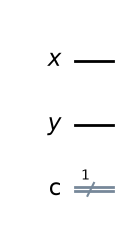

In [4]:
x = QuantumRegister(1, "x")
y = QuantumRegister(1, "y")

cr = ClassicalRegister(1, "c")

qc = QuantumCircuit(x, y, cr)
qc.draw("mpl")


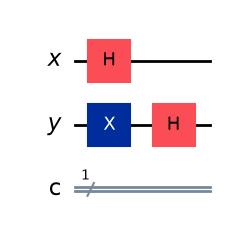

In [5]:
qc.h(x)
qc.x(y)
qc.h(y)
qc.draw("mpl")

In [6]:
def create_oracle(function_type):
    oracle = QuantumCircuit(2, name="Oracle")

    if function_type == "constant_0":
        pass

    elif function_type == "constant_1":
        oracle.x(1)

    elif function_type == "balanced_same_input":
        oracle.cx(0, 1)

    elif function_type == "balanced_not":
        oracle.cx(0, 1)
        oracle.x(1)

    return oracle

In [7]:
oracle = create_oracle("constant_1")
qc.append(oracle, [0, 1])



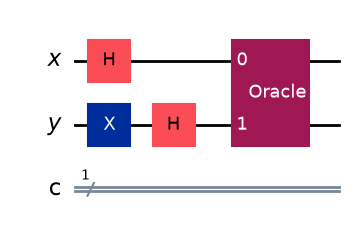

In [8]:
qc.draw('mpl')

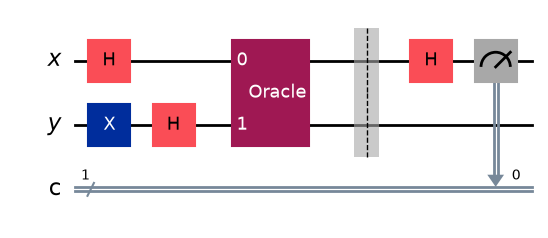

In [ ]:
qc.barrier()
qc.h(x)
qc.measure(x, cr)
qc.draw("mpl")


In [ ]:
aer_sim = AerSimulator()
transpiled_qc = transpile(qc, aer_sim)
job = aer_sim.run(transpiled_qc, shots=1)
result = job.result()
counts = result.get_counts(transpiled_qc)
print(counts)

{'0': 1}
